# Delivery Time Estimation: Feature Engineering

**Notebook 2 of the project.** Run the cells one by one from top to bottom (Shift + Enter).

<br>

## What this notebook does

Feature engineering means creating new input columns (features) that make the pattern easier for a model to learn. A raw latitude number tells the model very little. The distance between the restaurant and the customer tells it a lot.

| Item | Detail |
|---|---|
| Input | `data/processed/clean_data.csv` (made by notebook 1, 41,863 rows) |
| Output | `data/processed/features_data.csv` (the final model inputs + target) |

<br>

## Where this sits in the pipeline

```
Notebook 1: Load -> Quality audit -> Clean -> EDA
Notebook 2: Feature engineering -> Feature selection        <- you are here
Notebook 3: Train models -> Tune -> Evaluate -> Save model
App:        API + Streamlit UI
```

<br>

## Plan

1. Decide the prediction moment (this decides which columns we are allowed to use)
2. Build new features and check each one against delivery time
3. Test some ideas that turn out to be useless, and drop them
4. Pick the final feature list and save it

## Step 0: Setup and load the clean data

In [1]:
# os lets us check whether a file exists and create folders
import os

# numpy for maths, pandas for tables
import numpy as np
import pandas as pd

# matplotlib and seaborn for charts
import matplotlib.pyplot as plt
import seaborn as sns

# white background with light grid lines for every chart
sns.set_theme(style="whitegrid")

# one colour for all charts
COLOR = "#3B6EA5"

# show every column when a table is printed
pd.set_option("display.max_columns", 50)

In [2]:
# On your laptop the clean file is in data/processed/ (made by notebook 1)
DATA_PATH = "data/processed/clean_data.csv"

# In Google Colab: upload clean_data.csv with the folder icon on the left
if not os.path.exists(DATA_PATH):
    DATA_PATH = "clean_data.csv"

df = pd.read_csv(DATA_PATH)

# the column we want to predict
TARGET = "delivery_time_min"

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 41863 | Columns: 20


,order_id,rider_id,rider_age,rider_rating,restaurant_lat,restaurant_lon,delivery_lat,delivery_lon,order_date,time_ordered,time_picked,weather,traffic,vehicle_condition,order_type,vehicle_type,multiple_deliveries,festival,city_type,delivery_time_min
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitan,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitan,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitan,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitan,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitan,41


## Step 1: Decide the prediction moment

**We predict delivery time at the moment an order is assigned to a rider.**

This one decision tells us which columns are allowed as model inputs. A model may only use information that is already known at the moment of prediction.

| Known when the order is assigned | NOT known yet |
|---|---|
| Rider age and rating | Time the rider picks up the food |
| Vehicle type and condition | Actual delivery time (the target) |
| Order type and time of order | |
| Weather, traffic, festival, city type | |
| Restaurant and customer location | |
| Number of other orders the rider carries | |

Using pickup time would be **data leakage**: the model would look good in testing but fail in real use, because in real life that information doesn't exist yet when we need the prediction.

## Step 2: Build new features

### Feature 1: `distance_km` (distance between restaurant and customer)

We have latitude and longitude for both places. The Earth is round, so we cannot simply subtract the numbers. The **haversine formula** gives the straight-line distance over the Earth's surface:

1. Convert the latitudes and longitudes from degrees to radians
2. a = sin²(Δlat / 2) + cos(lat1) × cos(lat2) × sin²(Δlon / 2)
3. distance = 2 × R × arcsin(√a), where R = 6371 km (radius of the Earth)

In [3]:
def haversine_km(lat1, lon1, lat2, lon2):
    # radius of the Earth in kilometres
    R = 6371

    # numpy's sin and cos work in radians, so convert from degrees
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    # difference in latitude and longitude
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # the haversine formula
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


# Sanity check: 1 degree of latitude is known to be about 111 km
print("1 degree of latitude =", round(haversine_km(20, 77, 21, 77), 2), "km")

1 degree of latitude = 111.19 km


In [4]:
# apply the formula to every row at once (numpy works on whole columns)
df["distance_km"] = haversine_km(df["restaurant_lat"], df["restaurant_lon"],
                                 df["delivery_lat"], df["delivery_lon"])

df["distance_km"].describe().round(2)

count    41863.00
mean         9.72
std          5.60
min          1.47
25%          4.66
50%          9.19
75%         13.68
max         20.97
Name: distance_km, dtype: float64

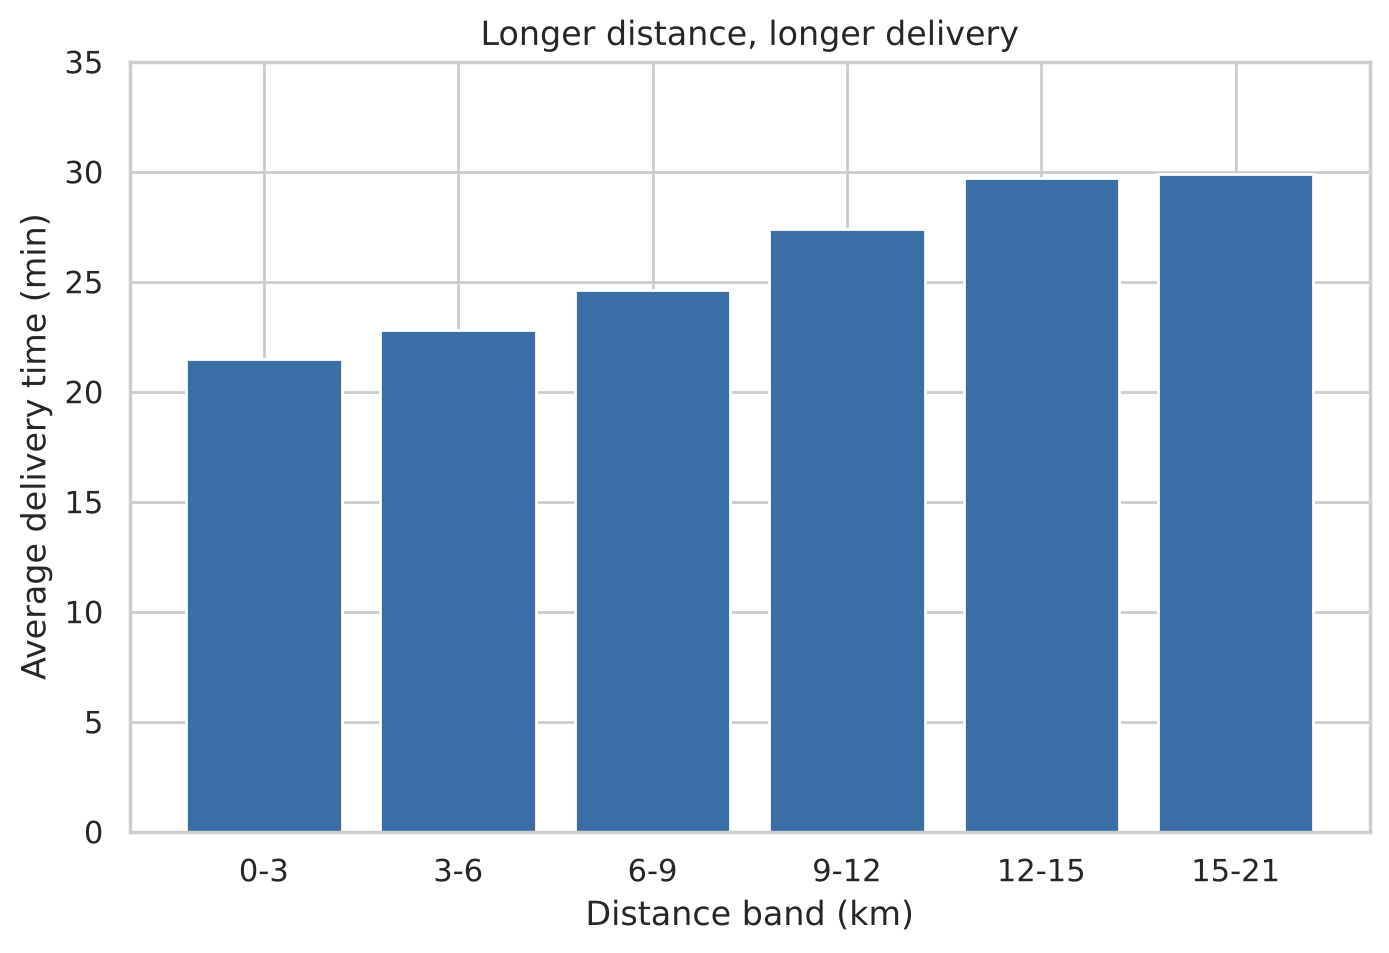

Correlation with delivery time: 0.321


,count,mean
distance_km,,
0-3,4311,21.5
3-6,7492,22.8
6-9,7544,24.6
9-12,7523,27.4
12-15,6965,29.7
15-21,8028,29.9


In [5]:
# group distances into bands of 3 km and look at the average delivery time in each band
bands = pd.cut(df["distance_km"], bins=[0, 3, 6, 9, 12, 15, 21],
               labels=["0-3", "3-6", "6-9", "9-12", "12-15", "15-21"])
distance_table = df.groupby(bands, observed=True)[TARGET].agg(["count", "mean"]).round(1)

plt.figure(figsize=(8, 5))
plt.bar(distance_table.index.astype(str), distance_table["mean"], color=COLOR)
plt.xlabel("Distance band (km)")
plt.ylabel("Average delivery time (min)")
plt.title("Longer distance, longer delivery")
plt.ylim(0, 35)
plt.show()

print("Correlation with delivery time:", round(df["distance_km"].corr(df[TARGET]), 3))
distance_table

**What we see:** distances run from 1.5 to 21 km (median 9.2 km). Average delivery time rises steadily, from 21.5 min (0 to 3 km) to about 30 min (above 12 km). The correlation is 0.32, so distance is one of the strongest features we have.

(Reminder from notebook 1: the delivery points in this dataset are partly synthetic, so this is a straight-line estimate, not a road distance.)

### Feature 2: `order_hour` (hour of the day the order was placed)

In [6]:
# time_ordered looks like "21:55", so the first 2 characters are the hour
df["order_hour"] = pd.to_numeric(df["time_ordered"].str[:2])

# rows where order time was missing now have a missing hour (filled later in the model pipeline)
print("Missing order_hour:", df["order_hour"].isna().sum())
df["order_hour"].value_counts().sort_index()

Missing order_hour: 1519


order_hour
0.0      396
8.0     1675
9.0     1792
10.0    1824
11.0    1803
12.0     826
13.0     719
14.0     723
15.0     800
16.0     649
17.0    3944
18.0    4133
19.0    4230
20.0    4195
21.0    4315
22.0    4193
23.0    4127
Name: count, dtype: int64

We already saw in notebook 1 that the hour matters: orders from 8 to 10 am take about 19.5 min, and orders from 19 to 21 take about 31 min.

### Feature 3: `is_peak_hour` (evening rush, 19:00 to 21:59)

The hour effect goes up and down during the day. A simple yes/no flag for the slowest hours makes the evening rush easy to learn, even for linear regression.

In [7]:
# 1 if the order was placed between 19:00 and 21:59, otherwise 0
df["is_peak_hour"] = df["order_hour"].between(19, 21).astype(float)

# if the hour is missing, the flag must be missing too (not 0)
df.loc[df["order_hour"].isna(), "is_peak_hour"] = np.nan

df.groupby("is_peak_hour")[TARGET].agg(["count", "mean"]).round(1)

,count,mean
is_peak_hour,,
0.0,27604,24.1
1.0,12740,31.0


**What we see:** peak-hour orders take 31.0 min on average, other orders 24.1 min. That's a gap of about 7 minutes.

### Features 4 and 5: `is_high_rated` and `is_age_30_plus`

Notebook 1 showed two sharp steps: delivery time drops at a rider rating of 4.5 and jumps at age 30. We turn each step into a yes/no flag.

Tree models can find these steps by themselves, but linear regression can only draw straight lines. The flags give it the step directly.

In [8]:
# 1 if rating is 4.5 or more, otherwise 0
df["is_high_rated"] = (df["rider_rating"] >= 4.5).astype(float)
# missing rating -> missing flag (filled later, not treated as "low rated")
df.loc[df["rider_rating"].isna(), "is_high_rated"] = np.nan

# 1 if age is 30 or more, otherwise 0
df["is_age_30_plus"] = (df["rider_age"] >= 30).astype(float)
df.loc[df["rider_age"].isna(), "is_age_30_plus"] = np.nan

print(df.groupby("is_high_rated")[TARGET].agg(["count", "mean"]).round(1), "\n")
print(df.groupby("is_age_30_plus")[TARGET].agg(["count", "mean"]).round(1))

               count  mean
is_high_rated             
0.0             7434  35.1
1.0            32666  24.3 

                count  mean
is_age_30_plus             
0.0             19911  23.0
1.0             20233  29.6


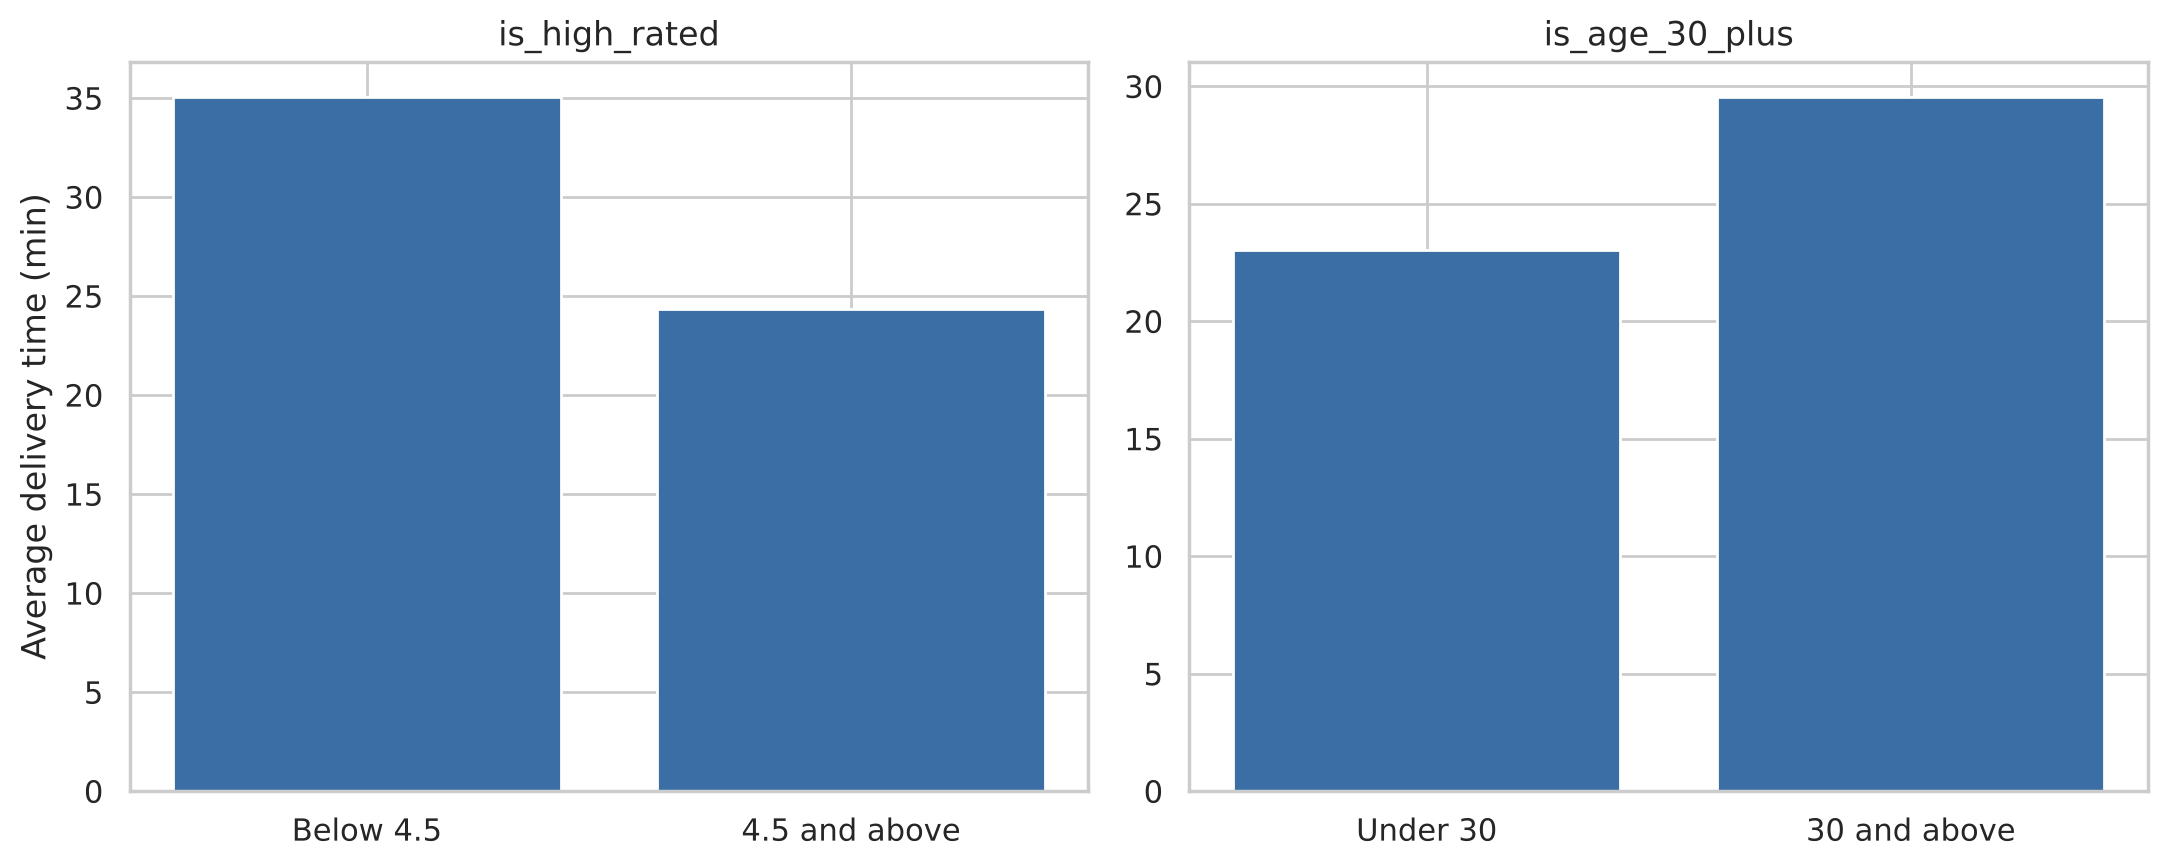

In [9]:
# both flags side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

rated = df.groupby("is_high_rated")[TARGET].mean()
axes[0].bar(["Below 4.5", "4.5 and above"], rated.values, color=COLOR)
axes[0].set_ylabel("Average delivery time (min)")
axes[0].set_title("is_high_rated")

aged = df.groupby("is_age_30_plus")[TARGET].mean()
axes[1].bar(["Under 30", "30 and above"], aged.values, color=COLOR)
axes[1].set_title("is_age_30_plus")

plt.tight_layout()
plt.show()

**What we see:**
- Riders rated 4.5 and above average 24.3 min, against 35.1 min below 4.5 (about 11 min faster).
- Riders aged 30 and above average 29.6 min, against 23.0 min under 30 (about 6.5 min slower).

## Step 3: Ideas we tested and dropped

A good feature must change delivery time. We tested three more ideas, and none of them did.

### Idea 1: day of the week / weekend

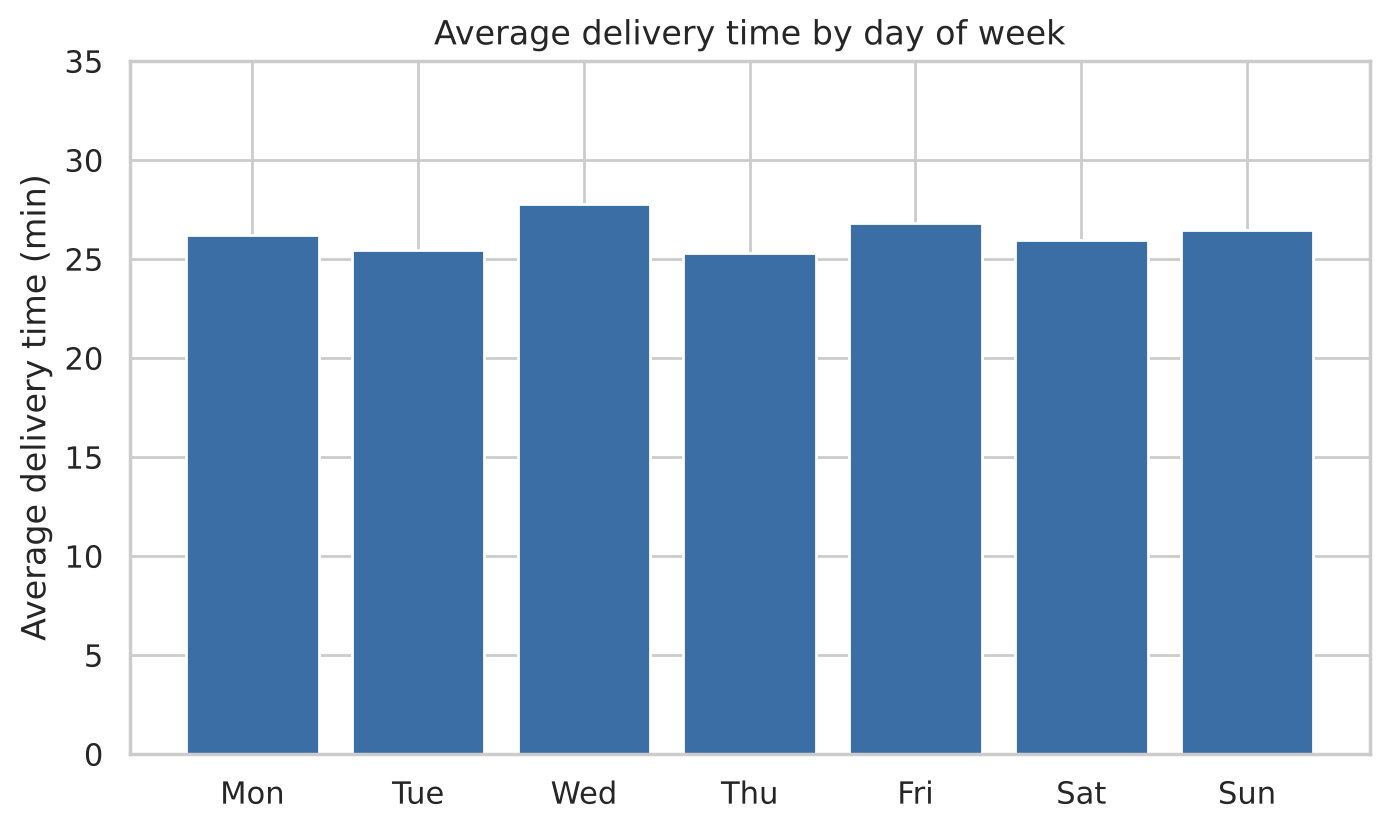

Weekday average: 26.35
Weekend average: 26.21


In [10]:
# convert the date text "12-02-2022" into a real date, then take the day of week (0 = Monday)
order_dates = pd.to_datetime(df["order_date"], format="%d-%m-%Y")
day_of_week = order_dates.dt.dayofweek

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
day_means = df.groupby(day_of_week)[TARGET].mean()

plt.figure(figsize=(8, 4.5))
plt.bar(day_names, day_means.values, color=COLOR)
plt.ylabel("Average delivery time (min)")
plt.title("Average delivery time by day of week")
plt.ylim(0, 35)
plt.show()

# weekend = Saturday (5) or Sunday (6)
is_weekend = day_of_week >= 5
print("Weekday average:", round(df.loc[~is_weekend, TARGET].mean(), 2))
print("Weekend average:", round(df.loc[is_weekend, TARGET].mean(), 2))

**Result:** every day sits between 25.3 and 27.8 min, and weekdays (26.35) and weekends (26.21) are the same. **Not used.**

In [11]:
# Idea 2: the city itself
# rider_id looks like "DEHRES17DEL01": the letters before "RES" are the city code (DEH = Dehradun)
city_code = df["rider_id"].str.split("RES").str[0]
city_code = city_code.rename("city_code")   # give the column a clear name for the table

city_table = df.groupby(city_code)[TARGET].agg(["count", "mean"]).round(1).sort_values("mean")
print("Number of cities:", len(city_table))
print("Fastest city average:", city_table["mean"].min(), "| Slowest city average:", city_table["mean"].max())
city_table.T

Number of cities: 22
Fastest city average: 26.0 | Slowest city average: 27.4


city_code,MYS,MUM,BANG,GOA,INDO,SUR,KNP,LUDH,PUNE,COIMB,KOC,RANCHI,KOL,HYD,CHEN,DEH,AGR,VAD,JAP,BHP,AURG,ALH
count,3004.0,3168.0,3182.0,609.0,3153.0,3182.0,673.0,687.0,3129.0,3161.0,701.0,2558.0,699.0,3175.0,3131.0,491.0,548.0,1576.0,3439.0,476.0,555.0,566.0
mean,26.0,26.0,26.1,26.1,26.1,26.1,26.2,26.2,26.3,26.3,26.3,26.4,26.4,26.4,26.4,26.6,26.7,26.7,26.7,26.7,26.9,27.4


**Result:** all 22 cities average between 26.0 and 27.4 min. Which city an order is in doesn't matter; the city *type* (Urban, Metropolitan, Semi-Urban) does, and we already have that column. **Not used.**

In [12]:
# Idea 3: food preparation wait = pickup time - order time
# (only to show it; this is the leakage column from step 1)
order_minutes = df["order_hour"] * 60 + pd.to_numeric(df["time_ordered"].str[3:5])
pickup_minutes = pd.to_numeric(df["time_picked"].str[:2]) * 60 + pd.to_numeric(df["time_picked"].str[3:5])

# % 1440 handles orders placed before midnight and picked up after it
prep_wait = (pickup_minutes - order_minutes) % 1440

print(prep_wait.value_counts().head())
print("\nCorrelation with delivery time:", round(prep_wait.corr(df[TARGET]), 3))

5.0     13567
15.0    13393
10.0    13384
Name: count, dtype: int64

Correlation with delivery time: -0.01


**Result:** the wait is always 5, 10 or 15 minutes, in equal shares, and its correlation with delivery time is -0.01 (none at all). It is leakage anyway (step 1), and it also carries no signal. **Not used.**

## Step 4: Check all numeric features together

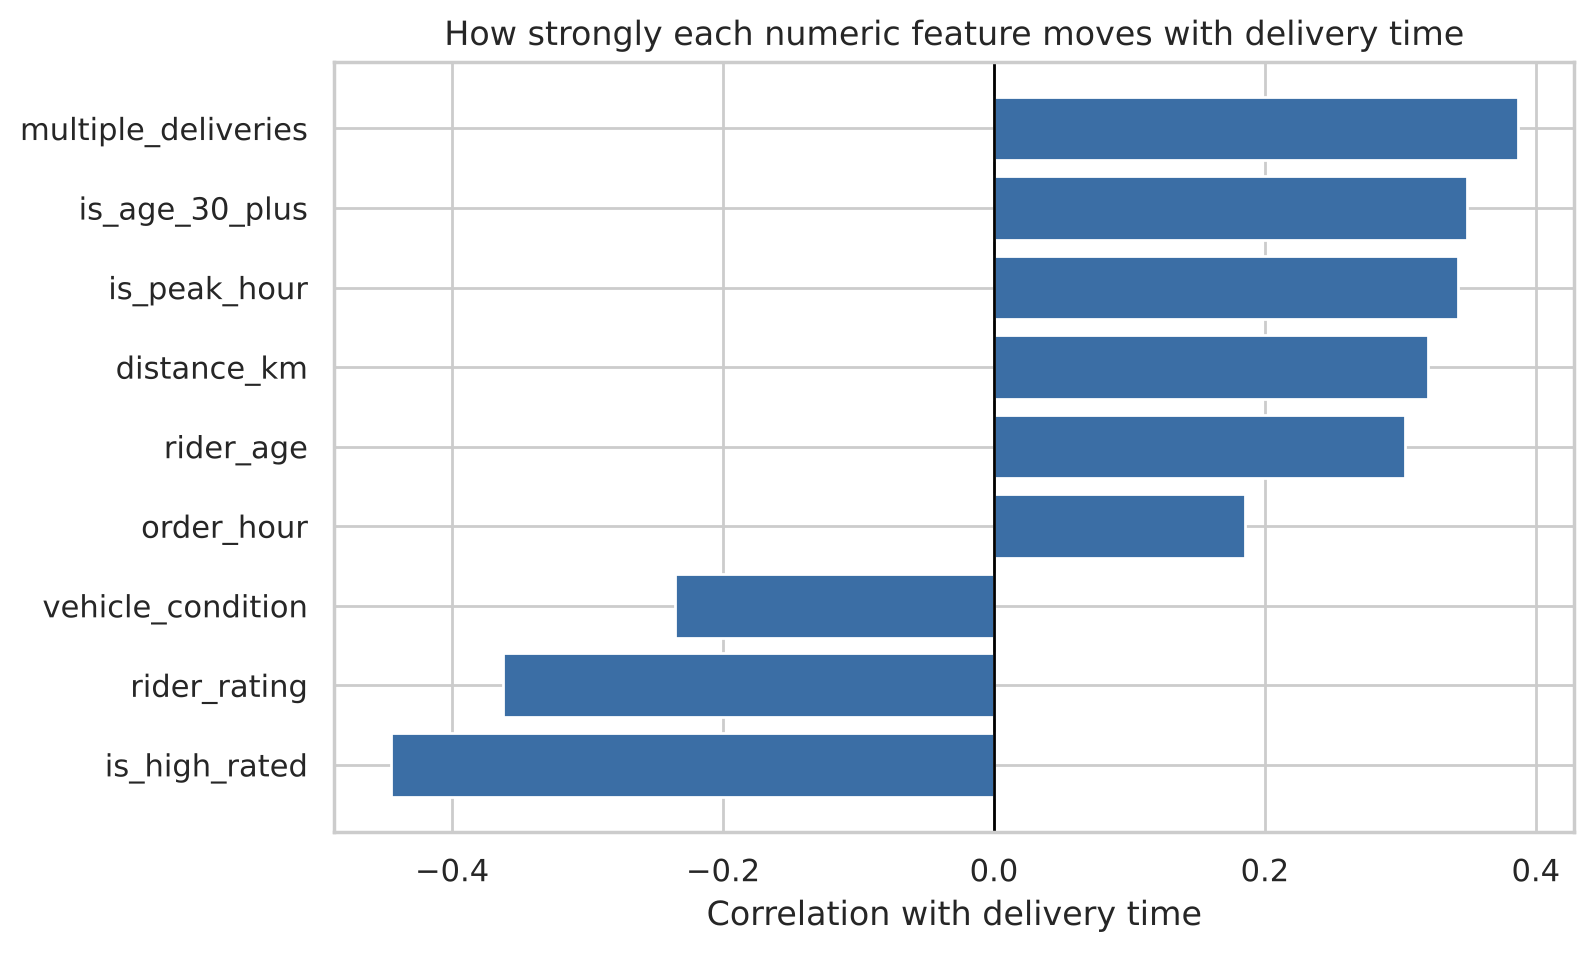

is_high_rated         -0.445
multiple_deliveries    0.387
rider_rating          -0.363
is_age_30_plus         0.349
is_peak_hour           0.342
distance_km            0.321
rider_age              0.303
vehicle_condition     -0.235
order_hour             0.185
dtype: float64

In [13]:
numeric_features = ["distance_km", "multiple_deliveries", "rider_rating", "is_high_rated",
                    "rider_age", "is_age_30_plus", "is_peak_hour", "vehicle_condition", "order_hour"]

# correlation of each numeric feature with delivery time
corr_with_target = df[numeric_features].corrwith(df[TARGET]).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(corr_with_target.index, corr_with_target.values, color=COLOR)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Correlation with delivery time")
plt.title("How strongly each numeric feature moves with delivery time")
plt.show()

corr_with_target.sort_values(key=abs, ascending=False).round(3)

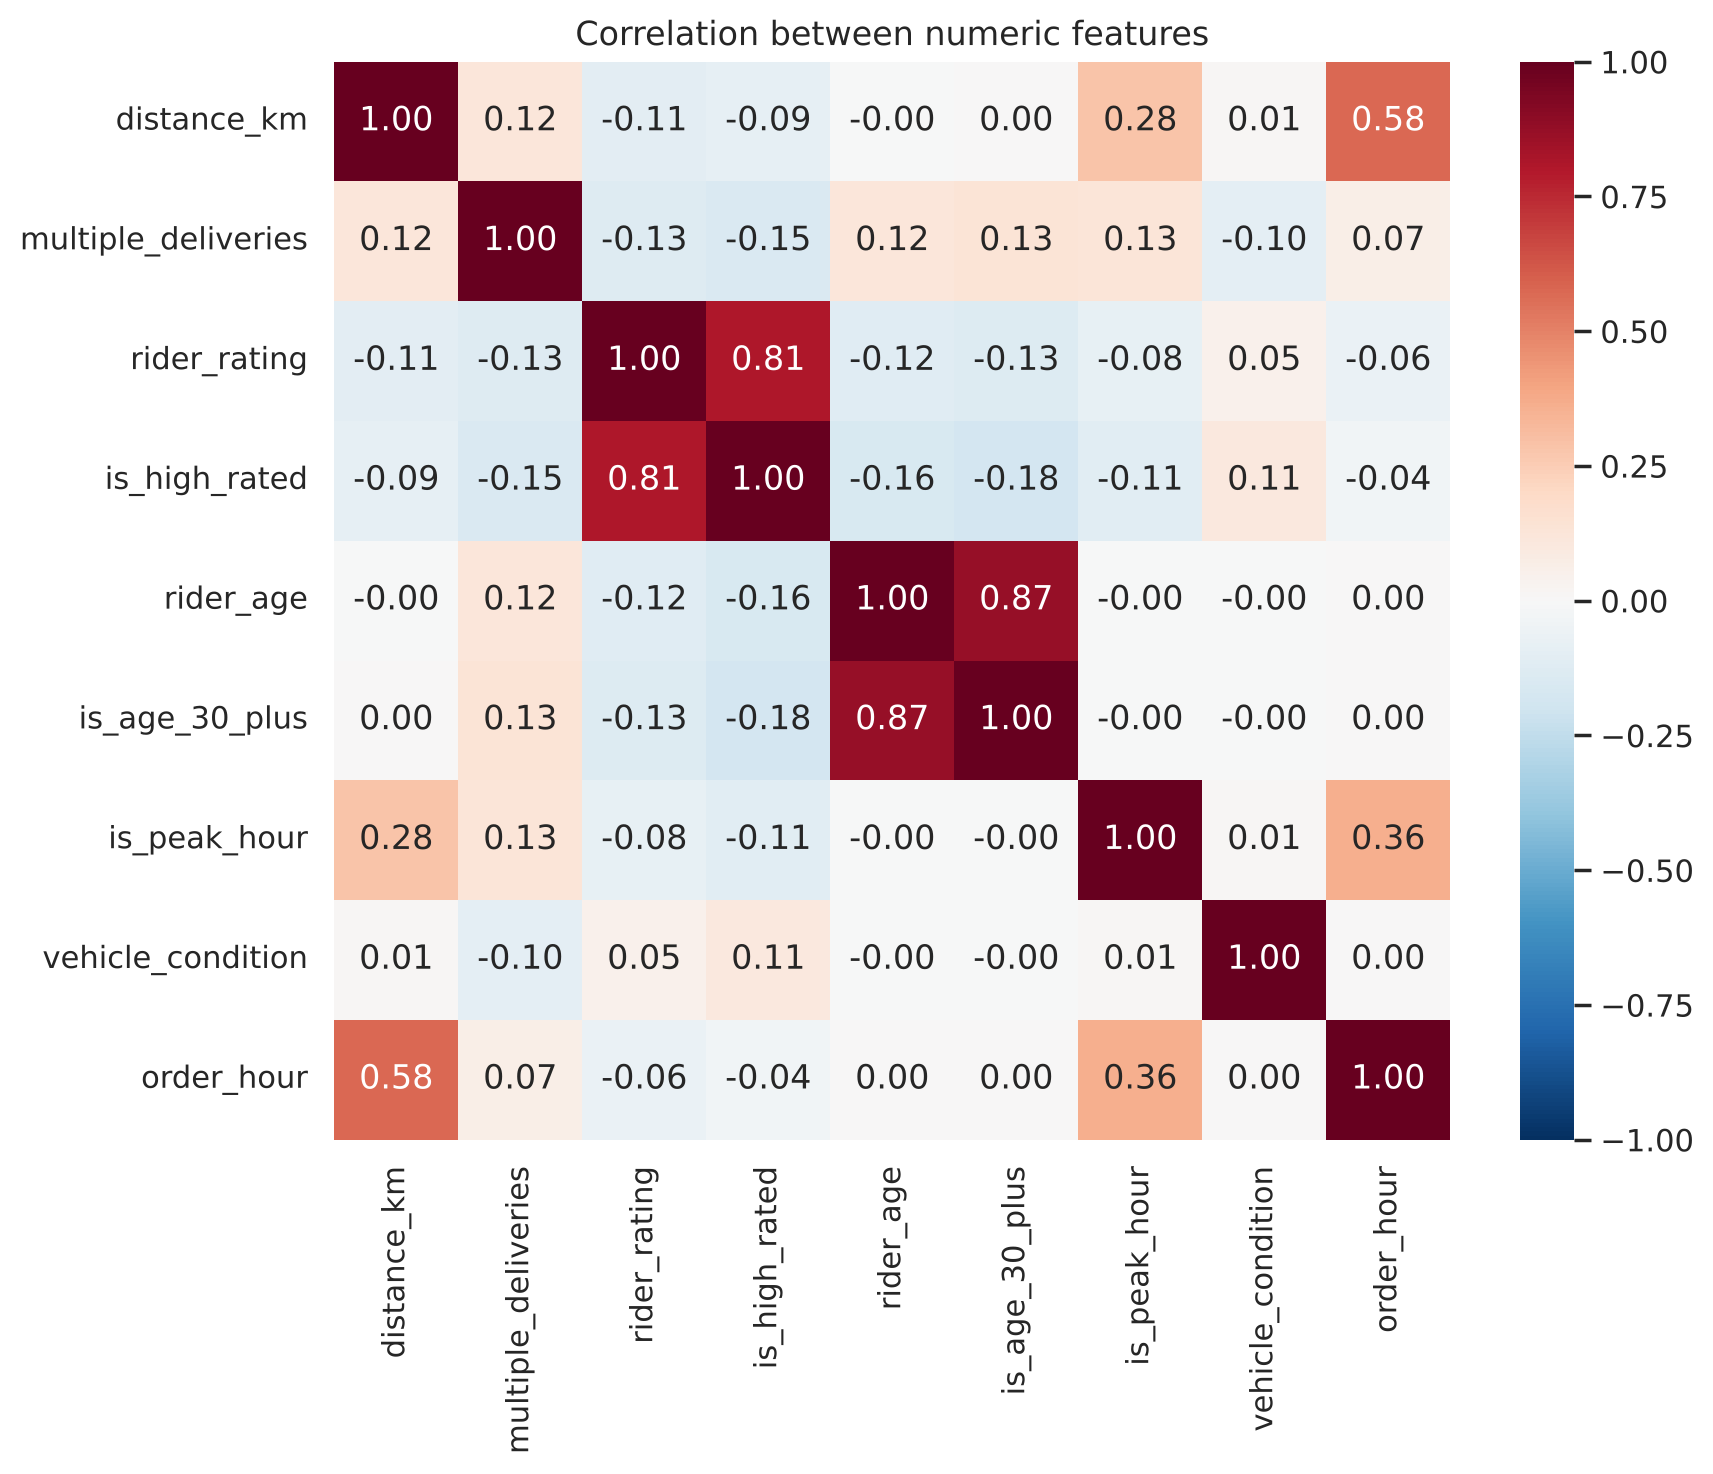

In [14]:
# Are any features almost copies of each other?
plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_features].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation between numeric features")
plt.show()

**What we see:**
- The strongest features are the rating flag (-0.45), multiple deliveries (+0.39), the age flag (+0.35), the peak-hour flag (+0.34) and distance (+0.32). The flags correlate more strongly than the raw rating (-0.36) and raw age (+0.30), which shows the step flags capture the pattern better.
- The flags correlate highly with the columns they come from (rating with is_high_rated 0.81, age with is_age_30_plus 0.87). We expected that: the flag holds the step, and the raw value holds the detail. Tree models are not hurt by this.
- Distance and order hour correlate at 0.58: in this data, later orders tend to be longer trips. That's moderate, well below the usual "too similar" level of about 0.85, so we keep both.
- Every other pair is weak, so we don't need PCA, and every feature stays explainable.

## Step 5: Final feature list

| Feature | Type | Where it comes from | Why it is useful |
|---|---|---|---|
| distance_km | Number | Haversine on the 4 coordinates | Longer trip, longer delivery |
| multiple_deliveries | Number | Raw column | Each extra order adds time |
| rider_rating | Number | Raw column | Better riders are faster |
| is_high_rated | 0 / 1 | rating >= 4.5 | Sharp step found in EDA |
| rider_age | Number | Raw column | Older riders are slower in this data |
| is_age_30_plus | 0 / 1 | age >= 30 | Sharp step found in EDA |
| vehicle_condition | Number | Raw column | Condition 0 is the slowest |
| order_hour | Number | From time_ordered | Time of day matters |
| is_peak_hour | 0 / 1 | hour 19 to 21 | Evening rush is the slowest |
| weather | Category | Raw column | Sunny fastest, fog slowest |
| traffic | Category | Raw column | Jam adds about 10 min |
| city_type | Category | Raw column | Semi-urban is much slower |
| festival | Category | Raw column | Festival days add about 20 min |
| vehicle_type | Category | Raw column | Motorcycles slightly slower |
| order_type | Category | Raw column | Kept because Option C asks for package type; EDA shows no effect, and feature importance will confirm |

<br>

**Columns we drop, and why:**

| Column | Reason |
|---|---|
| order_id | Just an ID, no meaning |
| rider_id | An ID; the city code inside it has no effect |
| restaurant_lat / lon, delivery_lat / lon | Replaced by distance_km |
| order_date | Day of week and weekend have no effect |
| time_ordered | Replaced by order_hour and is_peak_hour |
| time_picked | Leakage (not known when we predict), and no signal |

In [15]:
NUMERIC_FEATURES = ["distance_km", "multiple_deliveries", "rider_rating", "is_high_rated",
                    "rider_age", "is_age_30_plus", "vehicle_condition", "order_hour", "is_peak_hour"]

CATEGORICAL_FEATURES = ["weather", "traffic", "city_type", "festival", "vehicle_type", "order_type"]

# keep only the features and the target, in this order
features_data = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET]]

print("Rows:", features_data.shape[0], "| Feature columns:", features_data.shape[1] - 1, "+ 1 target")

# missing values left for the model pipeline to fill
features_data.isna().sum()

Rows: 41863 | Feature columns: 15 + 1 target


distance_km               0
multiple_deliveries     905
rider_rating           1763
is_high_rated          1763
rider_age              1719
is_age_30_plus         1719
vehicle_condition         0
order_hour             1519
is_peak_hour           1519
weather                 488
traffic                 474
city_type              1112
festival                215
vehicle_type              0
order_type                0
delivery_time_min         0
dtype: int64

In [16]:
# save the final table for notebook 3 (models)
os.makedirs("data/processed", exist_ok=True)
features_data.to_csv("data/processed/features_data.csv", index=False)

print("Saved data/processed/features_data.csv")
features_data.head()

Saved data/processed/features_data.csv


,distance_km,multiple_deliveries,rider_rating,is_high_rated,rider_age,is_age_30_plus,vehicle_condition,order_hour,is_peak_hour,weather,traffic,city_type,festival,vehicle_type,order_type,delivery_time_min
0,10.280582,3.0,4.2,0.0,36.0,1.0,2,21.0,1.0,Fog,Jam,Metropolitan,No,motorcycle,Snack,46
1,6.242319,1.0,4.7,1.0,21.0,0.0,1,14.0,0.0,Stormy,High,Metropolitan,No,motorcycle,Meal,23
2,13.787860,1.0,4.7,1.0,23.0,0.0,1,17.0,0.0,Sandstorms,Medium,Metropolitan,No,scooter,Drinks,21
3,2.930258,0.0,4.3,0.0,34.0,1.0,0,9.0,0.0,Sandstorms,Low,Metropolitan,No,motorcycle,Buffet,20
4,19.396618,1.0,4.7,1.0,24.0,0.0,1,19.0,1.0,Fog,Jam,Metropolitan,No,scooter,Snack,41


## Summary

- We fixed the prediction moment (order assigned to a rider) and so ruled out the pickup time column (leakage).
- We built **5 new features**: distance_km, order_hour, is_peak_hour, is_high_rated and is_age_30_plus.
- We tested and **dropped 3 ideas** that had no effect: day of week, city code, and preparation wait.
- The final table has **15 features** (9 numeric, 6 categorical) and the target, for 41,863 orders.
- Missing values are still there on purpose. Notebook 3 fills them inside the model pipeline using only the training data.

<br>

## Next: notebook 3 (models)

1. Split the data into training and test sets
2. Build the preprocessing pipeline (fill missing values, scale numbers, one-hot encode categories)
3. Train Linear Regression, Random Forest, XGBoost and an ANN
4. Tune with RandomizedSearchCV and check with 5-fold cross validation
5. Evaluate (MAE, RMSE, R²), explain with feature importance, and save the best model